Download fields: 7921, Classes: 4

[!] File tempcnn_best.pth found. Loading knowledge to continue training...

Start training...
Epoch 01 | Train Acc: 0.9465 | Val Acc: 0.9343 | Val Loss: 0.1923

Save tempcnn_best.pth
Epoch 02 | Train Acc: 0.9463 | Val Acc: 0.9293 | Val Loss: 0.2026
Epoch 03 | Train Acc: 0.9437 | Val Acc: 0.9331 | Val Loss: 0.1907

Save tempcnn_best.pth
Epoch 04 | Train Acc: 0.9497 | Val Acc: 0.9280 | Val Loss: 0.1900

Save tempcnn_best.pth
Epoch 05 | Train Acc: 0.9515 | Val Acc: 0.9331 | Val Loss: 0.1845

Save tempcnn_best.pth
Epoch 06 | Train Acc: 0.9536 | Val Acc: 0.9280 | Val Loss: 0.1949
Epoch 07 | Train Acc: 0.9522 | Val Acc: 0.9293 | Val Loss: 0.1899
Epoch 08 | Train Acc: 0.9523 | Val Acc: 0.9230 | Val Loss: 0.2454
Epoch 09 | Train Acc: 0.9509 | Val Acc: 0.9356 | Val Loss: 0.1991
Epoch 10 | Train Acc: 0.9550 | Val Acc: 0.9343 | Val Loss: 0.1843

Save tempcnn_best.pth
Epoch 11 | Train Acc: 0.9561 | Val Acc: 0.9331 | Val Loss: 0.1905
Epoch 12 | Train Acc: 0.9564 |

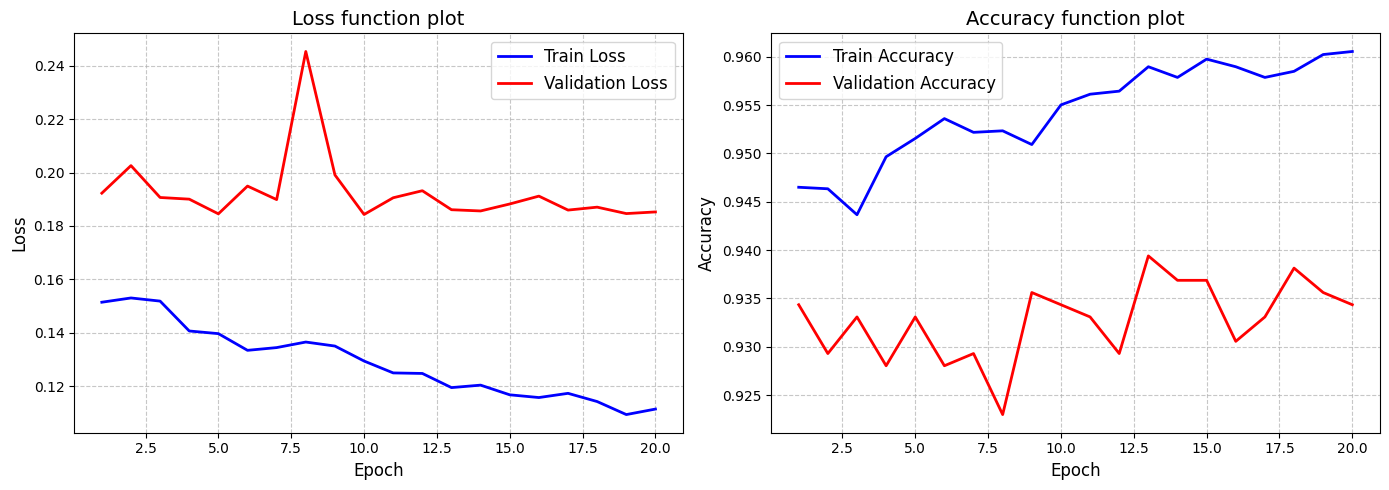


Test Acc: 0.9281 (92.81%)


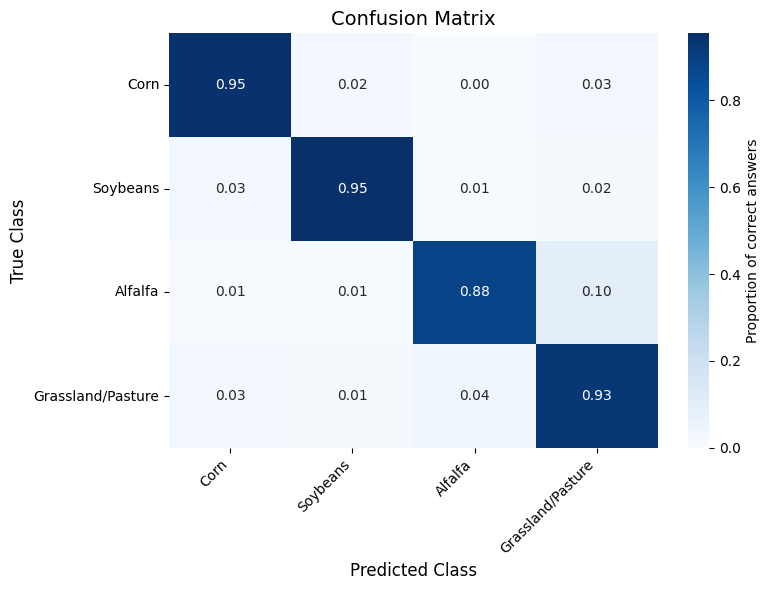

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os


def plot_learning_curves(train_losses, val_losses, train_accs, val_accs):
    epochs = range(1, len(train_losses) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(epochs, train_losses, 'b-', label='Train Loss', linewidth=2)
    axes[0].plot(epochs, val_losses, 'r-', label='Validation Loss', linewidth=2)
    axes[0].set_title('Loss function plot', fontsize=14)
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].legend(fontsize=12)
    axes[0].grid(True, linestyle='--', alpha=0.7)

    axes[1].plot(epochs, train_accs, 'b-', label='Train Accuracy', linewidth=2)
    axes[1].plot(epochs, val_accs, 'r-', label='Validation Accuracy', linewidth=2)
    axes[1].set_title('Accuracy function plot', fontsize=14)
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].legend(fontsize=12)
    axes[1].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Proportion of correct answers'})

    plt.title('Confusion Matrix', fontsize=14)
    plt.ylabel('True Class', fontsize=12)
    plt.xlabel('Predicted Class', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()



class TempCNN(nn.Module):
    def __init__(self, input_channels=5, num_classes=4, sequence_length=16):
        super(TempCNN, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_channels, out_channels=128, kernel_size=5, padding=2)
        self.bn1 = nn.BatchNorm1d(128)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=5, padding=2)
        self.bn2 = nn.BatchNorm1d(256)

        self.conv3 = nn.Conv1d(in_channels=256, out_channels=256, kernel_size=5, padding=2)
        self.bn3 = nn.BatchNorm1d(256)

        self.global_pool = nn.AdaptiveAvgPool1d(1)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.relu(self.bn3(self.conv3(x)))

        x = self.global_pool(x)
        x = x.squeeze(-1)
        x = self.dropout(x)
        logits = self.fc(x)
        return logits


#X_2025 = np.load('X_2025.npy')
#y_2025 = np.load('y_2025.npy')

#X_2026 = np.load('X_2026.npy')
#y_2026 = np.load('y_2026.npy')

#X = np.concatenate((X_2025, X_2026), axis=0)
#y = np.concatenate((y_2025, y_2026), axis=0)

#np.save('X.npy', X)
#np.save('y.npy', y)

X_numpy = np.load('X.npy')
y_numpy = np.load('y.npy')

X_numpy[:, 3, :] = (X_numpy[:, 3, :] - (-30.0)) / (5.0 - (-30.0))
X_numpy[:, 4, :] = (X_numpy[:, 4, :] - (-35.0)) / (0.0 - (-35.0))


with open('classes.json', 'r', encoding='utf-8') as f:
    classes_dict = json.load(f)
class_names = [k for k in classes_dict.keys() if k != '_channels']
NUM_CLASSES = len(class_names)

print(f"Download fields: {X_numpy.shape[0]}, Classes: {NUM_CLASSES}")

if X_numpy.shape[1] == 16 and X_numpy.shape[2] == 5:
    X_numpy = np.transpose(X_numpy, (0, 2, 1))


X_tensor = torch.tensor(X_numpy, dtype=torch.float32)
y_tensor = torch.tensor(y_numpy, dtype=torch.long)

X_temp, X_test, y_temp, y_test = train_test_split(
    X_tensor, y_tensor, test_size=0.10, random_state=42, stratify=y_tensor
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1/9, random_state=42, stratify=y_temp
)

BATCH_SIZE = 64
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = TempCNN(input_channels=5, num_classes=NUM_CLASSES).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00005, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)


if os.path.exists('tempcnn_best.pth'):
    print("\n[!] File tempcnn_best.pth found. Loading knowledge to continue training...")
    model.load_state_dict(torch.load('tempcnn_best.pth', weights_only=True))
else:
    print("\n[!] Weights file not found. Starting training from scratch...")


EPOCHS = 20
best_val_loss = float('inf')

train_loss_hist = []
val_loss_hist = []
train_acc_hist = []
val_acc_hist = []

print("\nStart training...")
for epoch in range(EPOCHS):
    # Train
    model.train()
    train_loss, correct_train, total_train = 0.0, 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        predicted = torch.argmax(outputs, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    avg_train_loss = train_loss / len(train_loader)
    train_acc = correct_train / total_train

    # Validation
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            predicted = torch.argmax(outputs, dim=1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    avg_val_loss = val_loss / len(val_loader)
    val_acc = correct_val / total_val

    scheduler.step(avg_val_loss)

    train_loss_hist.append(avg_train_loss)
    val_loss_hist.append(avg_val_loss)
    train_acc_hist.append(train_acc)
    val_acc_hist.append(val_acc)

    print(f"Epoch {epoch+1:02d} | Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | Val Loss: {avg_val_loss:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), 'tempcnn_best.pth')
        print("\nSave tempcnn_best.pth")

plot_learning_curves(train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist)



model.load_state_dict(torch.load('tempcnn_best.pth', weights_only=True))
model.eval()

test_correct = 0
all_true = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        outputs = model(inputs)
        predicted = torch.argmax(outputs, dim=1)

        test_correct += (predicted == labels).sum().item()
        all_true.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

test_accuracy = test_correct / len(y_test)
print(f"\nTest Acc: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")

plot_labels = [classes_dict[k]['name'] for k in class_names]
plot_confusion_matrix(all_true, all_preds, plot_labels)

In [5]:
import numpy as np
import torch
import json


X = np.load('X.npy')
y = np.load('y.npy')

with open('classes.json', 'r') as f:
    classes = json.load(f)

print(f"Shape X: {X.shape}")
print(f"Shape y: {y.shape}")
print(f"Classes: {classes}")

Shape X: (7921, 5, 16)
Shape y: (7921,)
Classes: {'0': {'cdl_code': 1, 'name': 'Corn', 'n_sampled': 2000, 'n_in_dataset': 1965}, '1': {'cdl_code': 5, 'name': 'Soybeans', 'n_sampled': 2000, 'n_in_dataset': 1973}, '2': {'cdl_code': 36, 'name': 'Alfalfa', 'n_sampled': 2000, 'n_in_dataset': 1989}, '3': {'cdl_code': 176, 'name': 'Grassland/Pasture', 'n_sampled': 2000, 'n_in_dataset': 1994}, '_channels': ['ndvi', 'evi', 'ndwi', 'vv', 'vh']}
